In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [3]:
%pip install pyarrow

Note: you may need to restart the kernel to use updated packages.


In [4]:
df = pd.read_parquet("yellow_tripdata_2025-01.parquet")

In [5]:
df.shape

(3475226, 20)

In [6]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-01-01 00:18:38,2025-01-01 00:26:59,1.0,1.60,1.0,N,229,237,1,10.0,3.5,0.5,3.00,0.0,1.0,18.00,2.5,0.0,0.0
1,1,2025-01-01 00:32:40,2025-01-01 00:35:13,1.0,0.50,1.0,N,236,237,1,5.1,3.5,0.5,2.02,0.0,1.0,12.12,2.5,0.0,0.0
2,1,2025-01-01 00:44:04,2025-01-01 00:46:01,1.0,0.60,1.0,N,141,141,1,5.1,3.5,0.5,2.00,0.0,1.0,12.10,2.5,0.0,0.0
3,2,2025-01-01 00:14:27,2025-01-01 00:20:01,3.0,0.52,1.0,N,244,244,2,7.2,1.0,0.5,0.00,0.0,1.0,9.70,0.0,0.0,0.0
4,2,2025-01-01 00:21:34,2025-01-01 00:25:06,3.0,0.66,1.0,N,244,116,2,5.8,1.0,0.5,0.00,0.0,1.0,8.30,0.0,0.0,0.0


In [7]:
df.dtypes

VendorID                          int32
tpep_pickup_datetime     datetime64[ns]
tpep_dropoff_datetime    datetime64[ns]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
store_and_fwd_flag               object
PULocationID                      int32
DOLocationID                      int32
payment_type                      int64
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
improvement_surcharge           float64
total_amount                    float64
congestion_surcharge            float64
Airport_fee                     float64
cbd_congestion_fee              float64
dtype: object

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3475226 entries, 0 to 3475225
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[ns]
 2   tpep_dropoff_datetime  datetime64[ns]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee           

In [9]:
df.isnull().values.any()

True

In [10]:
df.isnull().sum()

VendorID                      0
tpep_pickup_datetime          0
tpep_dropoff_datetime         0
passenger_count          540149
trip_distance                 0
RatecodeID               540149
store_and_fwd_flag       540149
PULocationID                  0
DOLocationID                  0
payment_type                  0
fare_amount                   0
extra                         0
mta_tax                       0
tip_amount                    0
tolls_amount                  0
improvement_surcharge         0
total_amount                  0
congestion_surcharge     540149
Airport_fee              540149
cbd_congestion_fee            0
dtype: int64

In [11]:
null_filter = df["passenger_count"].isnull()
missing = df[null_filter]
display(missing.head())

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
2935077,2,2025-01-01 00:39:17,2025-01-01 01:10:42,NaN,6.75,NaN,None,48,42,0,2.32,0.0,0.5,0.0,0.0,1.0,14.90,NaN,NaN,0.0
2935078,2,2025-01-01 00:33:40,2025-01-01 01:10:34,NaN,3.88,NaN,None,4,48,0,6.02,0.0,0.5,0.0,0.0,1.0,10.02,NaN,NaN,0.0
2935079,1,2025-01-01 00:09:32,2025-01-01 00:12:38,NaN,0.00,NaN,None,158,158,0,22.72,0.0,0.5,0.0,0.0,1.0,26.72,NaN,NaN,0.0
2935080,2,2025-01-01 00:21:42,2025-01-01 00:36:29,NaN,3.55,NaN,None,137,211,0,-2.35,0.0,0.5,0.0,0.0,1.0,5.80,NaN,NaN,0.0
2935081,2,2025-01-01 00:56:04,2025-01-01 01:06:11,NaN,1.55,NaN,None,140,233,0,5.06,0.0,0.5,0.0,0.0,1.0,9.06,NaN,NaN,0.0


In [12]:
missing["payment_type"].value_counts()

0    540149
Name: payment_type, dtype: int64

In [13]:
payment_zero=df[df["payment_type"]==0]
print("total payment_type = 0", len(payment_zero))

total payment_type = 0 540149


In [14]:
payment_zero["passenger_count"].isnull().value_counts()

True    540149
Name: passenger_count, dtype: int64

In [15]:
missing_percentage = len(missing) / len(df) * 100
print(missing_percentage)

15.54284527107014


In [16]:
missing_cols = ["passenger_count","RatecodeID","store_and_fwd_flag","congestion_surcharge","Airport_fee"]
all_five_missing = df[missing_cols].isnull().all(axis=1).sum()
print("rows with all five values missing:", all_five_missing)

rows with all five values missing: 540149


In [17]:
df["duration_min"] = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60

In [18]:
df["duration_min"].head()

0    8.350000
1    2.550000
2    1.950000
3    5.566667
4    3.533333
Name: duration_min, dtype: float64

In [19]:
df[["trip_distance",
    "duration_min","fare_amount","passenger_count"]].describe()

,trip_distance,duration_min,fare_amount,passenger_count
count,3.475226e+06,3.475226e+06,3.475226e+06,2.935077e+06
mean,5.855126e+00,1.501812e+01,1.708180e+01,1.297859e+00
std,5.646016e+02,3.871358e+01,4.634729e+02,7.507503e-01
min,0.000000e+00,-5.147232e+04,-9.000000e+02,0.000000e+00
25%,9.800000e-01,7.283333e+00,8.600000e+00,1.000000e+00
50%,1.670000e+00,1.170000e+01,1.211000e+01,1.000000e+00
75%,3.100000e+00,1.833333e+01,1.950000e+01,1.000000e+00
max,2.764236e+05,5.626317e+03,8.633721e+05,9.000000e+00


In [20]:
print("Negative distances:",
      (df["trip_distance"] < 0).sum())

print("Zero distances:",
      (df["trip_distance"] == 0).sum())

print("Non-positive durations:",
      (df["duration_min"] <= 0).sum())

print("Non-positive fares:",
      (df["fare_amount"] <= 0).sum())

Negative distances: 0
Zero distances: 90893
Non-positive durations: 2051
Non-positive fares: 145516


In [21]:
columns = ["tpep_pickup_datetime",
        "tpep_dropoff_datetime",
        "trip_distance",
        "duration_min","fare_amount","payment_type"]
display(df.nlargest(5,"trip_distance")[columns])

,tpep_pickup_datetime,tpep_dropoff_datetime,trip_distance,duration_min,fare_amount,payment_type
3275762,2025-01-22 21:04:00,2025-01-22 21:13:00,276423.57,9.0,-4.75,0
3188501,2025-01-19 14:51:00,2025-01-19 14:58:00,276099.95,7.0,9.13,0
3240337,2025-01-21 09:19:00,2025-01-21 09:45:00,222167.49,26.0,31.19,0
3112173,2025-01-16 10:47:00,2025-01-16 11:11:00,206137.99,24.0,24.89,0
3374854,2025-01-26 17:46:00,2025-01-26 17:59:00,202771.63,13.0,10.10,0


In [22]:
print(df[df["fare_amount"]<0]["payment_type"].value_counts())

0    84822
4    37405
2    13802
3     8075
1       14
Name: payment_type, dtype: int64


In [23]:
taxi = df[(df["trip_distance"]>0)&
          (df["trip_distance"]<= 100)&
          (df["duration_min"]>0)&
          (df["duration_min"]<180)&
          (df["fare_amount"] > 0)&
          (df["fare_amount"] <= 500)]
print("Original:",len(df))
print("After clearning:", len(taxi))

Original: 3475226
After clearning: 3251034


In [24]:
taxi[["trip_distance","duration_min","fare_amount","passenger_count"]].describe()

,trip_distance,duration_min,fare_amount,passenger_count
count,3.251034e+06,3.251034e+06,3.251034e+06,2.837879e+06
mean,3.167201e+00,1.467475e+01,1.794314e+01,1.295660e+00
std,4.141759e+00,1.134272e+01,1.619522e+01,7.484390e-01
min,1.000000e-02,1.666667e-02,1.000000e-02,0.000000e+00
25%,1.010000e+00,7.333333e+00,8.600000e+00,1.000000e+00
50%,1.700000e+00,1.168333e+01,1.280000e+01,1.000000e+00
75%,3.140000e+00,1.831667e+01,1.980000e+01,1.000000e+00
max,9.850000e+01,1.799667e+02,5.000000e+02,9.000000e+00


In [25]:
taxi[["trip_distance","duration_min","fare_amount"]].skew()

trip_distance    3.167175
duration_min     2.489310
fare_amount      3.608151
dtype: float64

In [26]:
taxi["payment_type"].value_counts()

1    2422685
0     413155
2     367519
4      35546
3      12129
Name: payment_type, dtype: int64

In [27]:
taxi["payment_type"].value_counts(normalize=True)*100

1    74.520445
0    12.708418
2    11.304680
4     1.093375
3     0.373081
Name: payment_type, dtype: float64

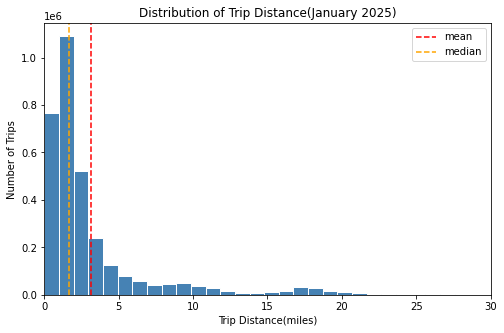

In [28]:
plt.figure(figsize=(8,5))
plt.hist(taxi["trip_distance"],bins=100, color="steelblue",edgecolor="white")
plt.axvline(taxi["trip_distance"].mean(), color="red", linestyle="--", label="mean")
plt.axvline(taxi["trip_distance"].median(), color="orange", linestyle="--", label="median")
plt.xlim(0, 30)
plt.title("Distribution of Trip Distance(January 2025)")
plt.xlabel("Trip Distance(miles)")
plt.ylabel("Number of Trips")
plt.legend()
plt.show()

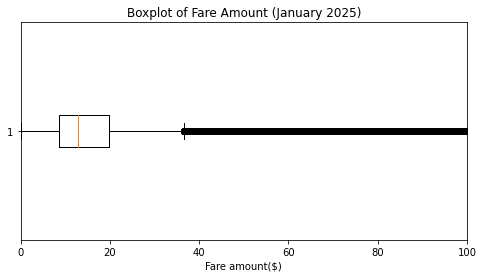

In [29]:
plt.figure(figsize=(8, 4))
plt.boxplot(taxi["fare_amount"], vert=False)
plt.xlim(0, 100)
plt.title("Boxplot of Fare Amount (January 2025)")
plt.xlabel("Fare amount($)")
plt.show()

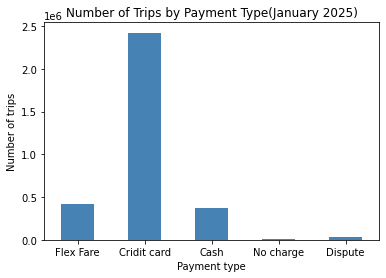

In [30]:
payment_counts = taxi["payment_type"].value_counts().sort_index()
payment_counts.index = ["Flex Fare","Cridit card","Cash","No charge","Dispute"]

payment_counts.plot(kind="bar", color="steelblue")

plt.title("Number of Trips by Payment Type(January 2025)")
plt.xlabel("Payment type")
plt.ylabel("Number of trips")
plt.xticks(rotation=0)
plt.show()

In [31]:
payments = taxi[(taxi["payment_type"]==1) | (taxi["payment_type"]==2)]

p = (payments["payment_type"]==1).mean()

print("number pf payments:", len(payments))
print("probablility of credit card payment:", round(p, 4))

number pf payments: 2790204
probablility of credit card payment: 0.8683


In [32]:
from scipy.special import comb

In [33]:
n = 20
k = 15

hand = comb(n,k) * p**k *(1 - p)**(n - k) 
print("hand calculation P(X=15):", round(hand, 4))
print("scipy P(X=15):", round(stats.binom.pmf(k, n, p), 4))

hand calculation P(X=15): 0.0739
scipy P(X=15): 0.0739


In [34]:
n=20

probability = stats.binom.sf(14, n, p)
print("P(X>=15):", round(probability, 4))

P(X>=15): 0.9609


In [35]:
from scipy.stats import binom

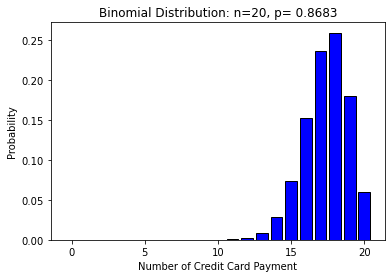

In [36]:
n=20

k = np.arange(0, n+1)
binom_pmf = binom.pmf(k, n, p)

plt.bar(k, binom_pmf, color="blue", edgecolor="black")
plt.title("Binomial Distribution: n=20, p= 0.8683")
plt.xlabel("Number of Credit Card Payment")
plt.ylabel("Probability")

plt.show()

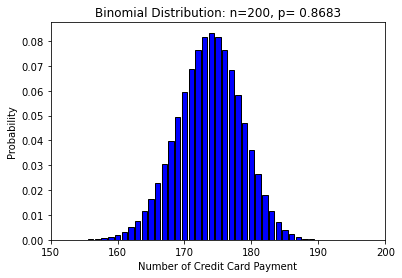

In [37]:
n = 200

k = np.arange(0, n+1)
binom_pmf = binom.pmf(k, n, p)

plt.bar(k, binom_pmf, color="blue", edgecolor="black")
plt.xlim(150, 200)

plt.title("Binomial Distribution: n=200, p= 0.8683")
plt.xlabel("Number of Credit Card Payment")
plt.ylabel("Probability")

plt.show()

In [38]:
print("n=20:", round(20*p, 2), round(20*(1-p), 2))
print("n=200:", round(200*p, 2), round(200*(1-p), 2))

n=20: 17.37 2.63
n=200: 173.66 26.34


In [40]:
print(df.shape)

(3475226, 21)


In [39]:
zone_trips = df[(df["PULocationID"]==161)&(df["tpep_pickup_datetime"]>="2025-01-01")&
               (df["tpep_pickup_datetime"]<"2025-02-01")]

print("Number of trips:", len(zone_trips))

Number of trips: 169977


In [42]:
morning = zone_trips[(zone_trips["tpep_pickup_datetime"].dt.dayofweek < 5)& (zone_trips["tpep_pickup_datetime"].dt.hour == 10)]

print("Number of pickups:", len(morning))

Number of pickups: 4824


In [43]:
all_minutes = pd.date_range("2025-01-01 10:00", "2025-01-31 10:59", freq="min")
all_minutes = all_minutes[(all_minutes.dayofweek < 5)& (all_minutes.hour == 10)]

print("Number of minutes:", len(all_minutes))

Number of minutes: 1380


In [44]:
counts = morning ["tpep_pickup_datetime"].dt.floor("min").value_counts()
counts = counts.reindex(all_minutes, fill_value=0)

print(counts.head())

2025-01-01 10:00:00    0
2025-01-01 10:01:00    1
2025-01-01 10:02:00    1
2025-01-01 10:03:00    1
2025-01-01 10:04:00    1
Name: tpep_pickup_datetime, dtype: int64


In [46]:
lambda_value = counts.mean()

print("Lambda:", round(lambda_value, 4))
print("Variance:", round(counts.var(), 4))

Lambda: 3.4957
Variance: 4.1109


In [48]:
import math 
from scipy.stats import poisson

In [49]:
x=3

hand = math.exp(-lambda_value) * lambda_value**x / math.factorial(x)

print("Hand calculation p(x=3):", round(hand, 4))
print("Scipy p(x=3):", round(poisson.pmf(x, lambda_value), 4))

Hand calculation p(x=3): 0.2159
Scipy p(x=3): 0.2159


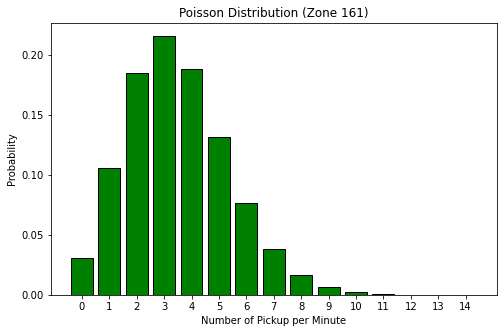

In [57]:
k = np.arange(0,15)
poisson_pmf = poisson.pmf(k, lambda_value)

plt.figure(figsize=(8, 5))
plt.bar(k, poisson_pmf, color="green",edgecolor="black")

plt.title("Poisson Distribution (Zone 161)")
plt.xlabel("Number of Pickup per Minute")
plt.ylabel("Probability")
plt.xticks(k)

plt.show()

In [58]:
observed = counts.value_counts(normalize=True).reindex(k, fill_value=0)

print(observed)

0     0.040580
1     0.128261
2     0.178261
3     0.191304
4     0.168841
5     0.127536
6     0.086232
7     0.052174
8     0.013043
9     0.006522
10    0.002899
11    0.003623
12    0.000000
13    0.000725
14    0.000000
Name: tpep_pickup_datetime, dtype: float64


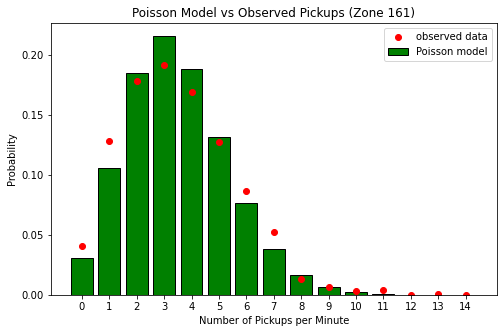

In [61]:
plt.figure(figsize=(8, 5))
plt.bar(k, poisson_pmf, color="green",edgecolor="black", label="Poisson model")
plt.plot(k, observed, "ro", label="observed data")

plt.title("Poisson Model vs Observed Pickups (Zone 161)")
plt.xlabel("Number of Pickups per Minute")
plt.ylabel("Probability")
plt.xticks(k)
plt.legend()

plt.show()

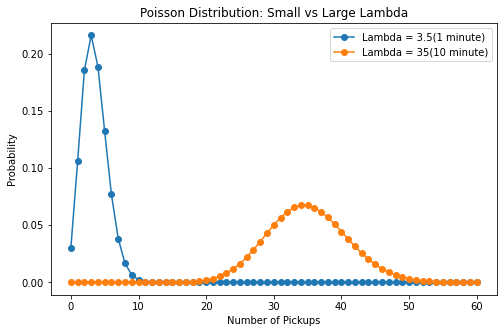

In [68]:
k = np.arange(0,61)
plt.figure(figsize=(8, 5))

plt.plot(k, poisson.pmf(k, lambda_value), marker="o", label="Lambda = 3.5(1 minute)")
plt.plot(k, poisson.pmf(k, lambda_value*10),marker="o", label="Lambda = 35(10 minute)")

plt.title("Poisson Distribution: Small vs Large Lambda")
plt.xlabel("Number of Pickups")
plt.ylabel("Probability")
plt.legend()

plt.savefig('fig7_poisson_large_lambda.png',dpi=300, bbox_inches='tight')
plt.show()

In [69]:
print("Skewness (Lambda = 3.5):",round(1 / np.sqrt(lambda_value), 2))
print("Skewness (Lambda = 35):",round(1 / np.sqrt(lambda_value * 10), 2))

Skewness (Lambda = 3.5): 0.53
Skewness (Lambda = 35): 0.17


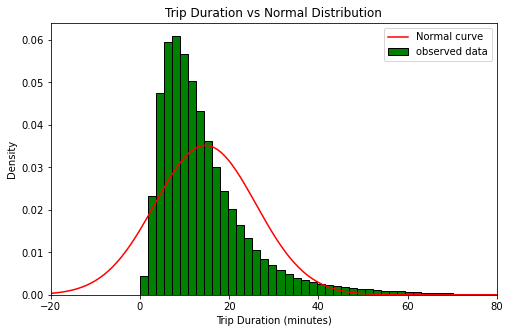

In [72]:
mu = taxi["duration_min"].mean()
sigma = taxi["duration_min"].std()

plt.figure(figsize=(8,5))

plt.hist(taxi["duration_min"], bins=100, density=True, color="green", edgecolor="black", label="observed data")

x = np.arange(-20, 180, 0.5)

plt.plot(x, stats.norm.pdf(x, mu, sigma), color="red", label="Normal curve")

plt.xlim(-20, 80)
plt.title("Trip Duration vs Normal Distribution")
plt.xlabel("Trip Duration (minutes)")
plt.ylabel("Density")
plt.legend()

plt.savefig('fig8_duration_normal.png',dpi=300, bbox_inches='tight')
plt.show()

In [74]:
duration = taxi["duration_min"]

within_1 = ((duration >= mu - sigma) & (duration <= mu + sigma)).mean()*100
within_2 =  ((duration >= mu - 2*sigma) & (duration <= mu + 2*sigma)).mean()*100
within_3 = ((duration >= mu - 3*sigma) & (duration <= mu + 3*sigma)).mean()*100

print("within 1 SD:", round(within_1, 2), "%")
print("within 2 SD:", round(within_2, 2), "%")
print("within 3 SD:", round(within_3, 2), "%")

within 1 SD: 84.47 %
within 2 SD: 95.35 %
within 3 SD: 97.9 %


In [75]:
prob_negative = stats.norm.cdf(0, mu, sigma)

print("Probability of negative duration:", round(prob_negative * 100,2), "%")

Probability of negative duration: 9.79 %


In [76]:
log_duration = np.log(duration)

print("Original skewness:", round(duration.skew(), 2))
print("Log skewness:", round(log_duration.skew(), 2))

Original skewness: 2.49
Log skewness: -0.44


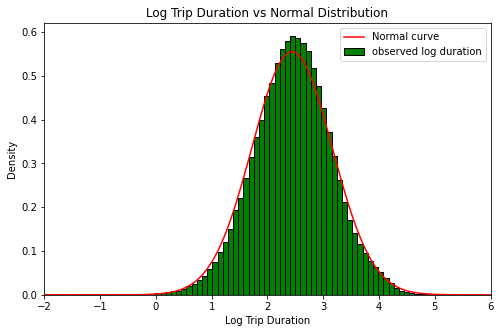

In [77]:
plt.figure(figsize=(8,5))

plt.hist(log_duration, bins=100, density=True, color="green", edgecolor="black", label="observed log duration")

x = np.arange(-5, 7, 0.05)

plt.plot(x, stats.norm.pdf(x, log_duration.mean(), log_duration.std()),color="red", label="Normal curve")

plt.xlim(-2, 6)
plt.title("Log Trip Duration vs Normal Distribution")
plt.xlabel("Log Trip Duration")
plt.ylabel("Density")
plt.legend()

plt.savefig('fig9_log_duration.png',dpi=300, bbox_inches='tight')
plt.show()